# 4. Implementação

**CatBoost aplicado à previsão de churn**

Atividade Final de Aprendizado de Máquina I · FATEC Jundiaí · Ciência de Dados

| Aluna | Professor | Tema |
|:--|:--|:--|
| Mariana Costa de Mello | Mateus Guilherme Fuini | CatBoost |

## Preparação

A mesma preparação é usada em todos os notebooks:

- `TotalCharges` vem como texto e os 11 valores em branco são de clientes com 0 meses de casa, então viram 0
- `customerID` sai porque é só um identificador
- Divisão estratificada em 60% treino, 20% validação e 20% teste, com semente 42

A primeira célula instala as bibliotecas; o `%%capture` esconde as mensagens da instalação.

In [1]:
%%capture
%pip install catboost shap category_encoders

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.precision", 3)
SEED = 42

df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].eq("Yes").astype(int)
cats = X.select_dtypes(exclude="number").columns.tolist()

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

## Qualidade dos dados

Tipos, nulos, valores únicos e duplicatas da base original.

In [3]:
bruto = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
print("Linhas duplicadas:", bruto.duplicated().sum())
print("TotalCharges em branco:", bruto["TotalCharges"].str.strip().eq("").sum(), "| tenure desses clientes:", bruto.loc[bruto["TotalCharges"].str.strip().eq(""), "tenure"].unique())
X.describe().T

Linhas duplicadas: 0
TotalCharges em branco: 11 | tenure desses clientes: [0]


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371,24.559,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734,2266.794,0.00,398.55,1394.55,3786.60,8684.80


| Verificação | Resultado |
|:--|:--|
| Duplicatas | Nenhuma |
| Nulos | Só os 11 `TotalCharges` em branco, todos com `tenure = 0`, preenchidos com 0 |
| Valores impossíveis | Nenhum: `tenure` de 0 a 72 meses, mensalidade de 18 a 119 |
| Vazamento | Nenhuma variável é posterior ao cancelamento; `customerID` foi removido |

> A base não tem data, então não dá para treinar no passado e testar no futuro. Por isso a divisão é aleatória e estratificada.

## Análise exploratória

Taxa de churn por categoria (linha tracejada = média geral) e distribuição das numéricas, só no treino.

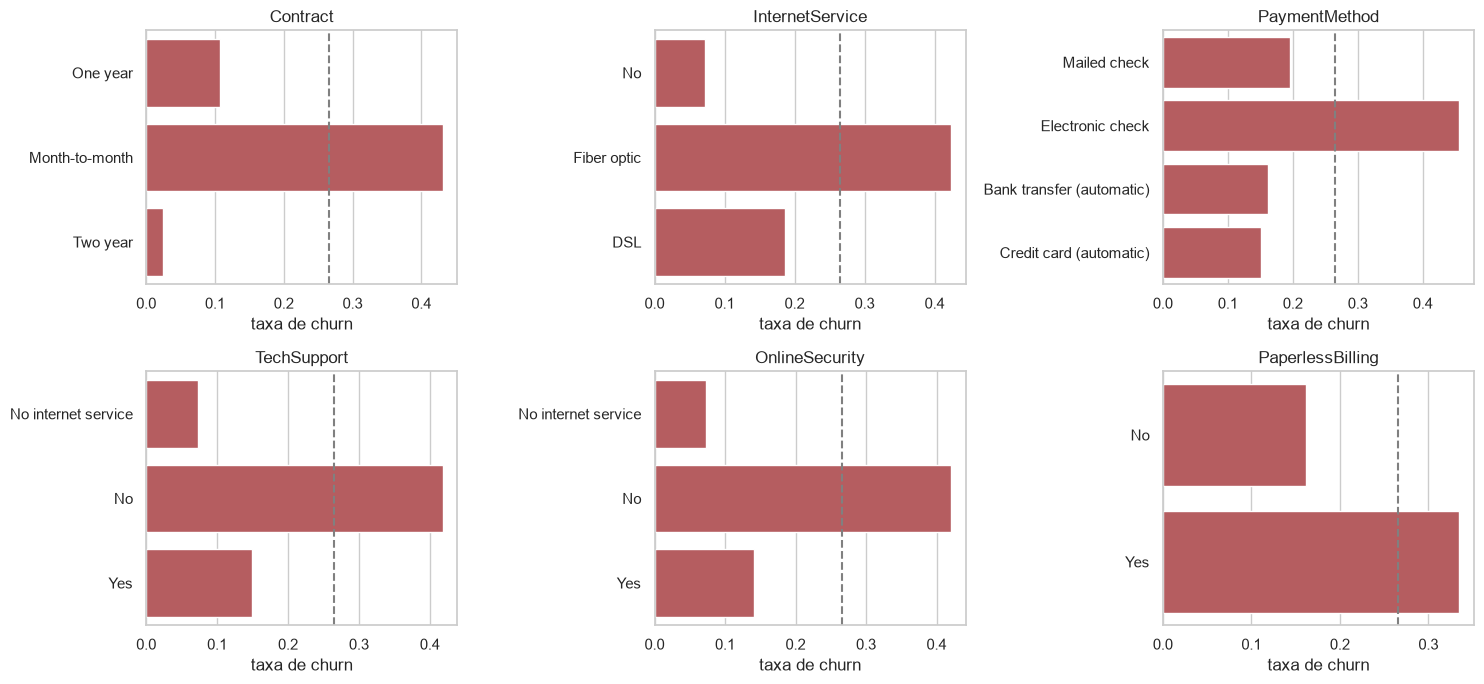

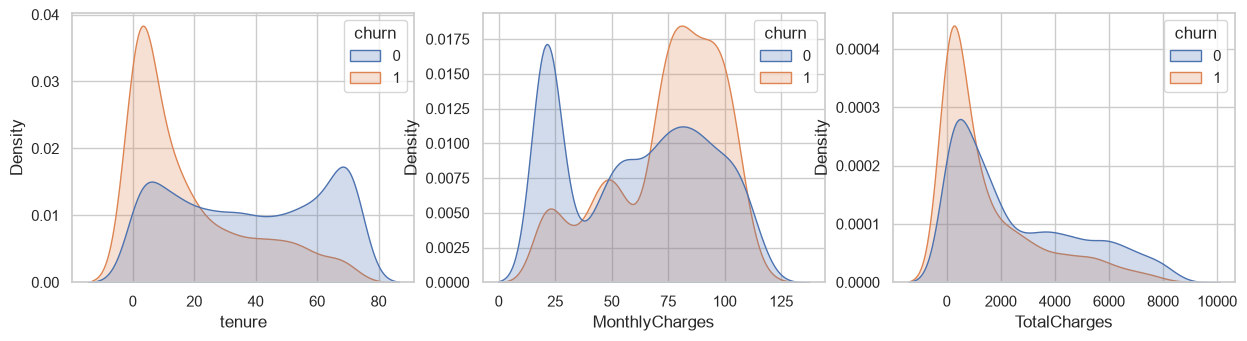

In [4]:
eda = X_train.assign(churn=y_train)
colunas = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, colunas):
    sns.barplot(data=eda, y=col, x="churn", errorbar=None, ax=ax, color="C3")
    ax.axvline(y_train.mean(), ls="--", color="gray")
    ax.set(xlabel="taxa de churn", ylabel="", title=col)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=eda, x=col, hue="churn", common_norm=False, fill=True, ax=ax)
plt.show()

- **Contrato mensal** concentra o churn; contratos de 1 e 2 anos quase não cancelam
- **Fibra ótica** e **cheque eletrônico** têm taxa acima da média
- Sem **suporte técnico** ou **segurança online**, o cliente cancela mais
- O churn se concentra nos **primeiros meses** e nas **mensalidades altas**

## Baselines

O modelo só é útil se ganhar de soluções simples. As referências, avaliadas na validação:

| Baseline | Regra |
|:--|:--|
| Classe majoritária | Diz sempre que o cliente fica |
| Contrato mensal | Diz que cancela quem tem contrato mensal |

A função `avaliar` junta as métricas usadas em todo o trabalho.

In [5]:
from sklearn.dummy import DummyClassifier

def avaliar(y_real, proba, limiar=0.5):
    pred = proba >= limiar
    return {"ROC-AUC": roc_auc_score(y_real, proba), "PR-AUC": average_precision_score(y_real, proba),
            "Precisão": precision_score(y_real, pred, zero_division=0), "Recall": recall_score(y_real, pred), "F1": f1_score(y_real, pred)}

taxa_contrato = y_train.groupby(X_train["Contract"]).mean()
resultados = {
    "Classe majoritária": avaliar(y_val, DummyClassifier().fit(X_train, y_train).predict_proba(X_val)[:, 1]),
    "Contrato mensal": avaliar(y_val, X_val["Contract"].map(taxa_contrato), limiar=0.3),
}
pd.DataFrame(resultados).T

,ROC-AUC,PR-AUC,Precisão,Recall,F1
Classe majoritária,0.500,0.265,0.000,0.000,0.000
Contrato mensal,0.725,0.404,0.418,0.866,0.563


## Primeiro modelo

Configuração inicial:

- `cat_features=cats`: as categóricas entram como texto
- `learning_rate=0.03` e `depth=6` como ponto de partida
- `eval_set` com a validação e `early_stopping_rounds=200`: o treino para quando a AUC da validação não melhora mais e fica com a melhor iteração

Árvores mantidas: 115


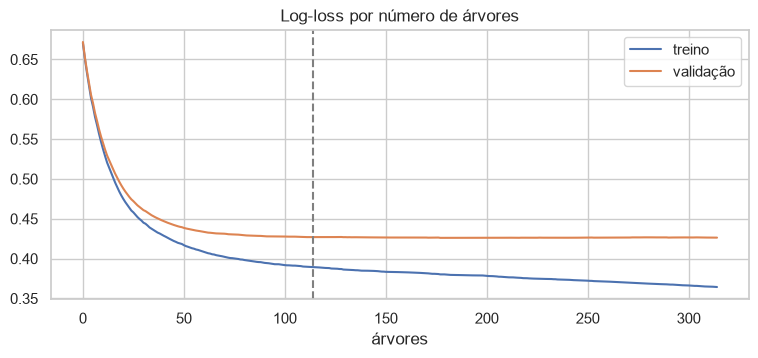

In [6]:
modelo = CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=6, eval_metric="AUC", early_stopping_rounds=200,
                            custom_metric=["Logloss"], random_seed=SEED, verbose=0, cat_features=cats)
modelo.fit(X_train, y_train, eval_set=(X_val, y_val))
print("Árvores mantidas:", modelo.tree_count_)

historico = pd.DataFrame({"treino": modelo.get_evals_result()["learn"]["Logloss"],
                          "validação": modelo.get_evals_result()["validation"]["Logloss"]})
historico.plot(figsize=(9, 3.5), title="Log-loss por número de árvores", xlabel="árvores")
plt.axvline(modelo.get_best_iteration(), ls="--", color="gray")
plt.show()

A perda no treino continua caindo, mas na validação estabiliza: o early stopping corta no melhor ponto.

### Comparação com os baselines (validação)

In [7]:
resultados["CatBoost"] = avaliar(y_val, modelo.predict_proba(X_val)[:, 1])
pd.DataFrame(resultados).T.style.format("{:.3f}").highlight_max(color="#d4e6f1")

,ROC-AUC,PR-AUC,Precisão,Recall,F1
Classe majoritária,0.500,0.265,0.000,0.000,0.000
Contrato mensal,0.725,0.404,0.418,0.866,0.563
CatBoost,0.837,0.648,0.682,0.516,0.588


> O CatBoost ganha dos dois baselines em ROC-AUC (0,837 contra 0,725) e PR-AUC (0,648 contra 0,404). O recall no limiar 0,5 é menor que o da regra do contrato, o que é esperado com classes desbalanceadas; o limiar é ajustado no Notebook 6.

## Previsão para clientes novos

O modelo recebe os dados no mesmo formato da base, com texto, e devolve a probabilidade de churn.

In [8]:
novos = X_val.iloc[[0]].assign(tenure=3, Contract="Month-to-month", InternetService="Fiber optic", PaymentMethod="Electronic check", TechSupport="No")
novos = pd.concat([novos, novos.assign(tenure=60, Contract="Two year", PaymentMethod="Credit card (automatic)", TechSupport="Yes")])
novos.assign(prob_churn=modelo.predict_proba(novos)[:, 1])[["tenure", "Contract", "InternetService", "PaymentMethod", "TechSupport", "prob_churn"]]

,tenure,Contract,InternetService,PaymentMethod,TechSupport,prob_churn
2103,3,Month-to-month,Fiber optic,Electronic check,No,0.625
2103,60,Two year,Fiber optic,Credit card (automatic),Yes,0.081
